# BITS Pilani – Deep Neural Networks CNN Assignment

**BITS ID:** 2026CT05135  
**Name:** Amit Jhariya  
**Email:** 2026ct05135@wilp.bits-pilani.ac.in  
**Date:** 26-Nov-2026

**Assignment:** Custom CNN vs. Transfer Learning for Cats vs Dogs Image Classification

> Run this notebook in Google Colab with a GPU runtime where possible. The notebook downloads the public Cats vs Dogs dataset through TensorFlow Datasets, selects 1,000 images per class (meeting the minimum 500 images per class), creates a stratified 90/10 train/test split, trains both models, calculates metrics from actual test predictions, and prints the required JSON.
>
> **Submission filename:** `2026CT05135_cnn_assignment.ipynb`  
> Submit only this `.ipynb` file. After running, download the executed notebook with all outputs visible. Add your own Colab/BITS Virtual Lab environment screenshot in the final section before submission.

## Pre-submission audit and Custom CNN revision notes

This notebook is organized against the supplied BITS Pilani CNN assignment instructions and strict-grading algorithm.

**Dataset and unchanged transfer-learning implementation**
- Dataset: balanced Cats vs Dogs subset (1,000 images per class; 2,000 total).
- Stratified 90/10 train/test split.
- ResNet50 transfer-learning architecture, training code, and evaluation code are retained unchanged.
- Both model heads use GlobalAveragePooling2D (GAP); neither uses Flatten.

**Changes made to the Custom CNN**
- Four convolutional blocks (32, 64, 128 and 256 filters) provide a progressively richer feature extractor.
- Mild image augmentation is used to reduce overfitting without heavily distorting the images.
- A stratified validation set is created explicitly, so both classes are represented proportionally in training and validation.
- Adam starts at a learning rate of 0.001; ReduceLROnPlateau lowers it when validation loss plateaus.
- Early stopping monitors validation loss but does not restore an earlier checkpoint. This keeps the evaluated model weights aligned with the assignment's required last-epoch training loss.
- Initial loss is read from epoch 1 and final loss from the last completed epoch. The reported reduction is calculated from those actual history values.

**Important execution note:** The revised Custom CNN has not been run in this editing step, so no new accuracy, loss-reduction percentage, or training time is claimed. Run the notebook from the beginning in Google Colab with a GPU enabled. The metrics, plots, analysis and JSON are generated from the actual execution. Do not manually edit reported results to meet a threshold.

Insert a genuine Colab/BITS Virtual Lab screenshot in the designated section and verify that the LMS folder name matches the student name before submission.


In [1]:
# Install required packages before importing TensorFlow Datasets.
# `importlib_resources` is provided by the PyPI package `importlib-resources`.
%pip -q install --upgrade tensorflow-datasets importlib-resources scikit-learn

print("Dependency installation cell completed.")

Dependency installation cell completed.


In [2]:
# Imports and reproducibility
import os
import json
import time
import random
import platform
import sys
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("Available GPU(s):", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
Available GPU(s): [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Dataset selection, loading and exploration

**Dataset:** Cats vs Dogs (TensorFlow Datasets public dataset).  
The notebook takes a reproducible balanced subset of 1,000 cat images and 1,000 dog images. This gives 2,000 images total and 1,000 images per class, exceeding the assignment minimum of 500 images per class. The train/test split is stratified at 90/10.

In [3]:
# Dataset metadata
dataset_name = "Cats vs Dogs (TensorFlow Datasets; balanced subset)"
dataset_source = "https://www.tensorflow.org/datasets/catalog/cats_vs_dogs"
n_classes = 2
image_shape = [224, 224, 3]
problem_type = "classification"
primary_metric = "accuracy"
metric_justification = (
    "Accuracy is the primary metric because the selected dataset is balanced "
    "with the same number of cat and dog images. Macro precision, recall and "
    "F1-score are also reported to assess both classes equally."
)

IMG_SIZE = (224, 224)
IMAGES_PER_CLASS = 1000
BATCH_SIZE = 32
CUSTOM_EPOCHS = 30       # Upper limit; early stopping may stop sooner.
TL_EPOCHS = 8
CUSTOM_LEARNING_RATE = 0.001
EARLY_STOPPING_PATIENCE = 6
LR_REDUCTION_PATIENCE = 2

print("Dataset:", dataset_name)
print("Source:", dataset_source)
print("Classes: cat, dog")
print("Images selected per class:", IMAGES_PER_CLASS)
print("Image size:", image_shape)
print("Custom CNN maximum epochs:", CUSTOM_EPOCHS)
print("Custom CNN initial learning rate:", CUSTOM_LEARNING_RATE)
print("Transfer learning epochs:", TL_EPOCHS)
print("Primary metric:", primary_metric)
print("Justification:", metric_justification)


Dataset: Cats vs Dogs (TensorFlow Datasets; balanced subset)
Source: https://www.tensorflow.org/datasets/catalog/cats_vs_dogs
Classes: cat, dog
Images selected per class: 1000
Image size: [224, 224, 3]
Custom CNN maximum epochs: 30
Custom CNN initial learning rate: 0.001
Transfer learning epochs: 8
Primary metric: accuracy
Justification: Accuracy is the primary metric because the selected dataset is balanced with the same number of cat and dog images. Macro precision, recall and F1-score are also reported to assess both classes equally.


In [4]:
# Download/load the public dataset and create a balanced subset.
# TensorFlow Datasets handles the source dataset download and decoding.
(ds_all, ds_info) = tfds.load(
    "cats_vs_dogs",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

label_names = ds_info.features["label"].names
print("Dataset label names:", label_names)

# Take exactly 1,000 examples from each class.
cat_ds = ds_all.filter(lambda image, label: tf.equal(label, 0)).take(IMAGES_PER_CLASS)
dog_ds = ds_all.filter(lambda image, label: tf.equal(label, 1)).take(IMAGES_PER_CLASS)
balanced_ds = cat_ds.concatenate(dog_ds).shuffle(
    buffer_size=2 * IMAGES_PER_CLASS, seed=SEED, reshuffle_each_iteration=False
)

# Resize and collect uint8 images. Keeping uint8 until model input reduces RAM use.
images_list, labels_list = [], []
for image, label in tfds.as_numpy(balanced_ds):
    image = tf.image.resize(image, IMG_SIZE, method="bilinear").numpy()
    image = np.clip(image, 0, 255).astype(np.uint8)
    images_list.append(image)
    labels_list.append(int(label))

X = np.stack(images_list)
y = np.asarray(labels_list, dtype=np.int32)

class_counts = {label_names[i]: int(np.sum(y == i)) for i in range(len(label_names))}
n_samples = int(len(y))
samples_per_class = (
    f"min: {min(class_counts.values())}, "
    f"max: {max(class_counts.values())}, "
    f"avg: {np.mean(list(class_counts.values())):.0f}"
)

assert n_samples == 2 * IMAGES_PER_CLASS, (
    f"Expected {2 * IMAGES_PER_CLASS} images but loaded {n_samples}. "
    "Check dataset download and availability."
)
assert min(class_counts.values()) >= 500, "Dataset requirement of 500 images per class is not met."

print("Total selected images:", n_samples)
print("Class counts:", class_counts)
print("Samples per class:", samples_per_class)
print("Image tensor shape:", X.shape)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.HBRPOI_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset label names: ['cat', 'dog']
Total selected images: 2000
Class counts: {'cat': 1000, 'dog': 1000}
Samples per class: min: 1000, max: 1000, avg: 1000
Image tensor shape: (2000, 224, 224, 3)


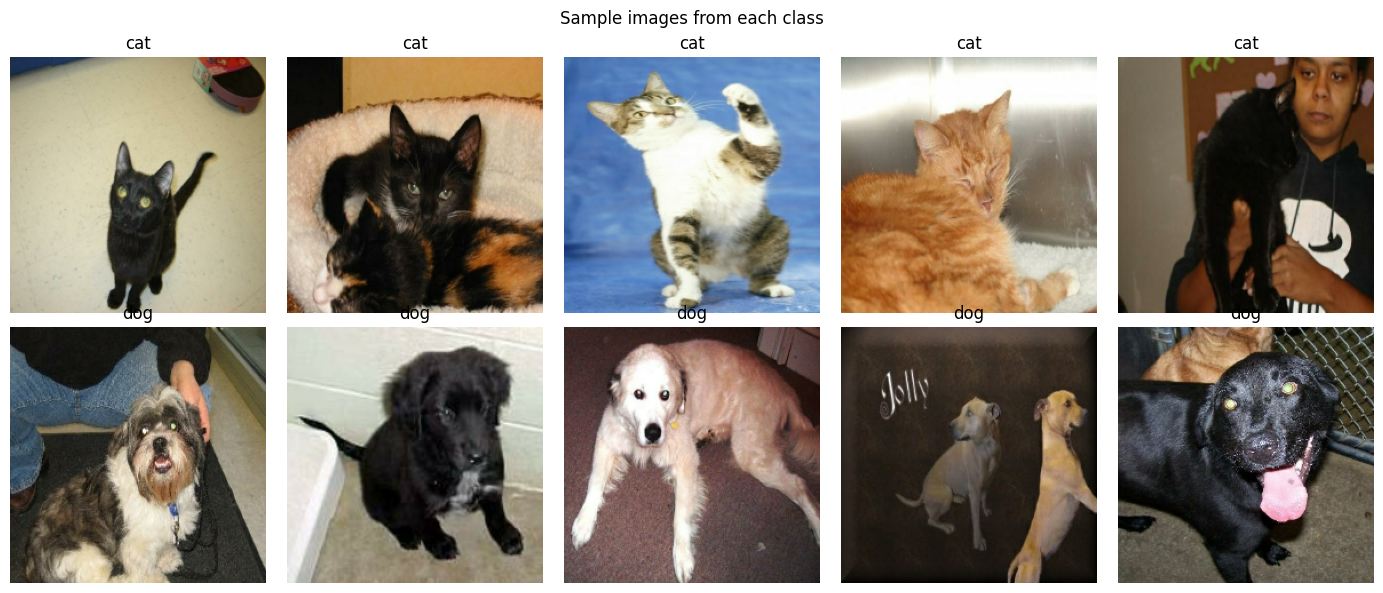

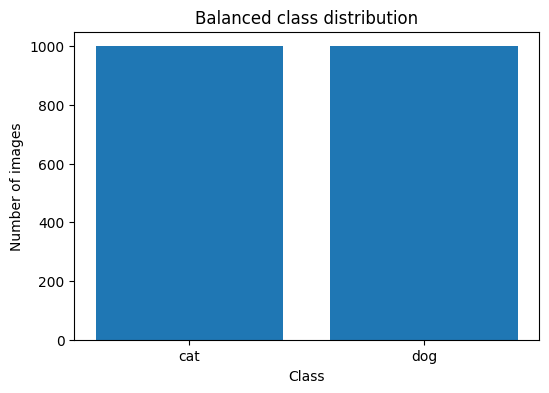

Pixel range: 0 to 255
Data type: uint8


In [5]:
# Visualize sample images and class distribution
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for class_id, class_name in enumerate(label_names):
    class_indices = np.where(y == class_id)[0][:5]
    for j, idx in enumerate(class_indices):
        axes[class_id, j].imshow(X[idx])
        axes[class_id, j].set_title(class_name)
        axes[class_id, j].axis("off")
plt.suptitle("Sample images from each class")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.bar(list(class_counts.keys()), list(class_counts.values()))
plt.title("Balanced class distribution")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.show()

print("Pixel range:", int(X.min()), "to", int(X.max()))
print("Data type:", X.dtype)

### 1.1 Preprocessing and train/test split

Images are resized to 224×224×3. A stratified 90/10 split preserves the class balance in both partitions. Pixel scaling/preprocessing is included inside each model so the models receive the correct input representation.

In [6]:
# Stratified 90/10 split
indices = np.arange(n_samples)
train_idx, test_idx = train_test_split(
    indices, test_size=0.10, random_state=SEED, stratify=y
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

train_test_ratio = "90/10"
train_samples = int(len(train_idx))
test_samples = int(len(test_idx))

print("Train/test split:", train_test_ratio)
print("Training samples:", train_samples)
print("Test samples:", test_samples)
print("Training class counts:", {
    label_names[i]: int(np.sum(y_train == i)) for i in range(n_classes)
})
print("Test class counts:", {
    label_names[i]: int(np.sum(y_test == i)) for i in range(n_classes)
})

Train/test split: 90/10
Training samples: 1800
Test samples: 200
Training class counts: {'cat': 900, 'dog': 900}
Test class counts: {'cat': 100, 'dog': 100}


## 2. Part 1 – Custom CNN implementation (5 marks)

The custom CNN uses multiple Conv2D and MaxPooling2D blocks, followed by **GlobalAveragePooling2D** and a Softmax output. It deliberately does not use Flatten.

In [7]:
# Custom CNN architecture: four convolutional blocks + mandatory GAP
def build_custom_cnn(input_shape, n_classes):
    inputs = tf.keras.Input(shape=input_shape, name="image")

    # Normalize uint8 image values from [0, 255] to [0, 1].
    x = tf.keras.layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)

    # Mild augmentation: avoid distorting animal features excessively.
    x = tf.keras.layers.RandomFlip("horizontal", name="random_flip")(x)
    x = tf.keras.layers.RandomRotation(0.03, name="random_rotation")(x)
    x = tf.keras.layers.RandomZoom(0.08, name="random_zoom")(x)
    x = tf.keras.layers.RandomContrast(0.08, name="random_contrast")(x)

    # Convolutional blocks learn increasingly complex visual features.
    for filters in [32, 64, 128, 256]:
        x = tf.keras.layers.Conv2D(
            filters, 3, padding="same", use_bias=False,
            kernel_initializer="he_normal"
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)

        x = tf.keras.layers.Conv2D(
            filters, 3, padding="same", use_bias=False,
            kernel_initializer="he_normal"
        )(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D(pool_size=2)(x)

    # Mandatory Global Average Pooling; no Flatten layer is used.
    x = tf.keras.layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    x = tf.keras.layers.Dense(
        128, activation="relu",
        kernel_initializer="he_normal",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4)
    )(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(
        n_classes, activation="softmax", name="classifier"
    )(x)

    return tf.keras.Model(inputs, outputs, name="custom_cnn_gap")


custom_cnn = build_custom_cnn(tuple(image_shape), n_classes)
custom_learning_rate = CUSTOM_LEARNING_RATE
custom_batch_size = BATCH_SIZE
custom_optimizer = "Adam"
custom_loss_function = "sparse_categorical_crossentropy"

custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=custom_learning_rate),
    loss=custom_loss_function,
    metrics=["accuracy"]
)

# Architecture checks required by the assignment.
assert sum(isinstance(layer, tf.keras.layers.Conv2D) for layer in custom_cnn.layers) >= 2
assert any(isinstance(layer, tf.keras.layers.GlobalAveragePooling2D) for layer in custom_cnn.layers)
assert not any(isinstance(layer, tf.keras.layers.Flatten) for layer in custom_cnn.layers)
assert custom_cnn.layers[-1].activation == tf.keras.activations.softmax

custom_cnn.summary()


Model: "custom_cnn_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           51

 Total params: 1,208,290 (4.61 MB)

 Trainable params: 1,206,370 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [8]:
# Train Custom CNN using a stratified validation set.
# The final reported loss and test metrics refer to the same final-epoch weights.
print("\\nCUSTOM CNN TRAINING")

custom_X_train, custom_X_val, custom_y_train, custom_y_val = train_test_split(
    X_train, y_train,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train
)

print("Custom CNN training samples:", len(custom_X_train))
print("Custom CNN validation samples:", len(custom_X_val))
print("Custom CNN training class counts:", {
    label_names[i]: int(np.sum(custom_y_train == i)) for i in range(n_classes)
})
print("Custom CNN validation class counts:", {
    label_names[i]: int(np.sum(custom_y_val == i)) for i in range(n_classes)
})

custom_cnn_start_time = time.time()

custom_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    min_delta=1e-4,
    restore_best_weights=False,
    verbose=1
)
custom_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

custom_history = custom_cnn.fit(
    custom_X_train, custom_y_train,
    validation_data=(custom_X_val, custom_y_val),
    epochs=CUSTOM_EPOCHS,
    batch_size=custom_batch_size,
    shuffle=True,
    callbacks=[custom_early_stopping, custom_reduce_lr],
    verbose=1
)

custom_cnn_training_time = time.time() - custom_cnn_start_time

# The assignment defines final loss as the last epoch's training loss.
# EarlyStopping does not restore earlier weights, so the evaluated model
# corresponds to this final epoch and the reported final loss.
custom_best_epoch_index = int(np.argmin(custom_history.history["val_loss"]))
custom_best_epoch = custom_best_epoch_index + 1
custom_cnn_initial_loss = float(custom_history.history["loss"][0])
custom_cnn_final_loss = float(custom_history.history["loss"][-1])
custom_cnn_loss_reduction_pct = (
    (custom_cnn_initial_loss - custom_cnn_final_loss)
    / custom_cnn_initial_loss * 100.0
)

print(f"Training time: {custom_cnn_training_time:.2f} seconds")
print(f"Epochs completed: {len(custom_history.history['loss'])}")
print(f"Best validation-loss epoch (diagnostic): {custom_best_epoch}")
print(f"Initial training loss (epoch 1): {custom_cnn_initial_loss:.6f}")
print(f"Final training loss (last epoch): {custom_cnn_final_loss:.6f}")
print(f"Training-loss reduction: {custom_cnn_loss_reduction_pct:.2f}%")
print(f"Best validation loss: {min(custom_history.history['val_loss']):.6f}")
print("Evaluated Custom CNN weights: final completed epoch (no best-weight restoration).")


\nCUSTOM CNN TRAINING
Custom CNN training samples: 1620
Custom CNN validation samples: 180
Custom CNN training class counts: {'cat': 810, 'dog': 810}
Custom CNN validation class counts: {'cat': 90, 'dog': 90}
Epoch 1/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 40s 408ms/step - accuracy: 0.5599 - loss: 0.8032 - val_accuracy: 0.5000 - val_loss: 0.8660 - learning_rate: 0.0010
Epoch 2/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 15s 295ms/step - accuracy: 0.5827 - loss: 0.7178 - val_accuracy: 0.5222 - val_loss: 0.7502 - learning_rate: 0.0010
Epoch 3/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 16s 313ms/step - accuracy: 0.5951 - loss: 0.6824 - val_accuracy: 0.5000 - val_loss: 0.7780 - learning_rate: 0.0010
Epoch 4/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 16s 314ms/step - accuracy: 0.6327 - loss: 0.6728 - val_accuracy: 0.5333 - val_loss: 0.7286 - learning_rate: 0.0010
Epoch 5/30
51/51 ━━━━━━━━━━━━━━━━━━━━ 15s 298ms/step - accuracy: 0.6599 - loss: 0.6420 - val_accuracy: 0.5444 - val_loss: 0.7445 - learning_rate: 0.0010
Epoch 6/30
51/51 ━━━━━━━━━

In [9]:
# Evaluate custom CNN on the held-out test set
custom_probabilities = custom_cnn.predict(X_test, batch_size=BATCH_SIZE, verbose=1)
custom_y_pred = np.argmax(custom_probabilities, axis=1)

custom_cnn_accuracy = float(accuracy_score(y_test, custom_y_pred))
custom_cnn_precision = float(precision_score(y_test, custom_y_pred, average="macro", zero_division=0))
custom_cnn_recall = float(recall_score(y_test, custom_y_pred, average="macro", zero_division=0))
custom_cnn_f1 = float(f1_score(y_test, custom_y_pred, average="macro", zero_division=0))

print("\nCUSTOM CNN TEST METRICS")
print(f"Accuracy:  {custom_cnn_accuracy:.4f}")
print(f"Precision: {custom_cnn_precision:.4f}")
print(f"Recall:    {custom_cnn_recall:.4f}")
print(f"F1-score:  {custom_cnn_f1:.4f}")
print(classification_report(y_test, custom_y_pred, target_names=label_names, zero_division=0))

print("Custom CNN predicted class counts:", {
    label_names[i]: int(np.sum(custom_y_pred == i)) for i in range(n_classes)
})


7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 240ms/step

CUSTOM CNN TEST METRICS
Accuracy:  0.7700
Precision: 0.7865
Recall:    0.7700
F1-score:  0.7666
              precision    recall  f1-score   support

         cat       0.72      0.89      0.79       100
         dog       0.86      0.65      0.74       100

    accuracy                           0.77       200
   macro avg       0.79      0.77      0.77       200
weighted avg       0.79      0.77      0.77       200

Custom CNN predicted class counts: {'cat': 124, 'dog': 76}


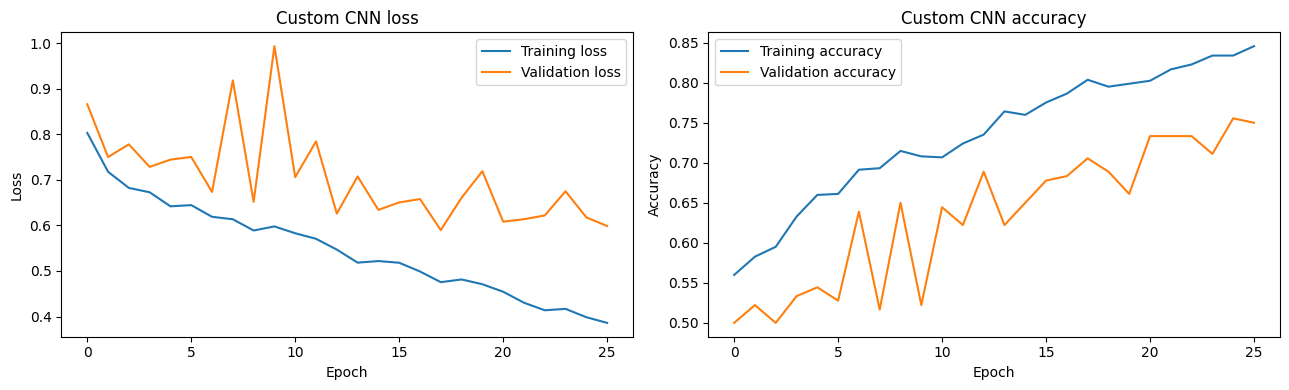

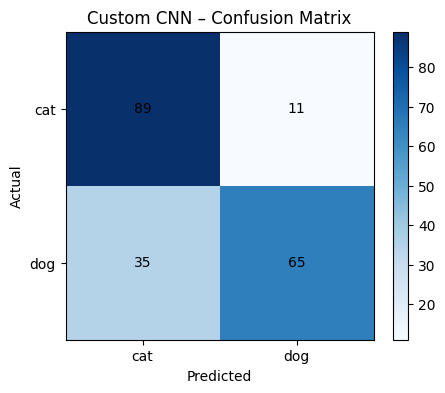

In [10]:
# Custom CNN training curves and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(custom_history.history["loss"], label="Training loss")
axes[0].plot(custom_history.history["val_loss"], label="Validation loss")
axes[0].set_title("Custom CNN loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(custom_history.history["accuracy"], label="Training accuracy")
axes[1].plot(custom_history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Custom CNN accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

cm_custom = confusion_matrix(y_test, custom_y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm_custom, cmap="Blues")
plt.title("Custom CNN – Confusion Matrix")
plt.xticks(range(n_classes), label_names)
plt.yticks(range(n_classes), label_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
for i in range(n_classes):
    for j in range(n_classes):
        plt.text(j, i, cm_custom[i, j], ha="center", va="center")
plt.colorbar()
plt.show()

## 3. Part 2 – Transfer learning implementation (5 marks)

ResNet50 pretrained on ImageNet is used as the feature extractor. All base-model layers are frozen for this assignment's feature-extraction stage. A custom classification head uses GlobalAveragePooling2D, Dropout and a Softmax Dense output.

In [11]:
# Build ResNet50 transfer learning model
pretrained_model_name = "ResNet50"

def build_transfer_learning_model(base_model_name, input_shape, n_classes):
    if base_model_name.lower() != "resnet50":
        raise ValueError("This notebook implements ResNet50 as the selected allowed base model.")

    inputs = tf.keras.Input(shape=input_shape)
    # ResNet50 expects its ImageNet preprocessing convention.
    x = tf.keras.applications.resnet50.preprocess_input(inputs)

    base_model = tf.keras.applications.ResNet50(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape
    )
    base_model.trainable = False
    x = base_model(x, training=False)

    x = tf.keras.layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    outputs = tf.keras.layers.Dense(n_classes, activation="softmax", name="classifier")(x)

    model = tf.keras.Model(inputs, outputs, name="resnet50_transfer_learning")
    return model, base_model

transfer_model, transfer_base_model = build_transfer_learning_model(
    pretrained_model_name, tuple(image_shape), n_classes
)

tl_learning_rate = 0.001
tl_epochs = TL_EPOCHS
tl_batch_size = BATCH_SIZE
tl_optimizer = "Adam"
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=tl_learning_rate),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

frozen_layers = sum(1 for layer in transfer_base_model.layers if not layer.trainable)
trainable_layers = sum(1 for layer in transfer_model.layers if layer.trainable)
total_parameters = int(transfer_model.count_params())
trainable_parameters = int(sum(np.prod(v.shape) for v in transfer_model.trainable_weights))

print("Base model:", pretrained_model_name)
print("Frozen base-model layers:", frozen_layers)
print("Trainable model layers (including custom head):", trainable_layers)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")
print("Global Average Pooling: YES")
transfer_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Base model: ResNet50
Frozen base-model layers: 175
Trainable model layers (including custom head): 4
Total parameters: 23,591,810
Trainable parameters: 4,098
Global Average Pooling: YES


Model: "resnet50_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer[0][0] │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add[0][0]         │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ classifier (Dense)  │ (None, 2)         │      4,098 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,591,810 (90.00 MB)

 Trainable params: 4,098 (16.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [12]:
# Train transfer learning model
print("\nTRANSFER LEARNING TRAINING")
tl_start_time = time.time()

tl_history = transfer_model.fit(
    X_train, y_train,
    validation_split=0.10,
    epochs=tl_epochs,
    batch_size=tl_batch_size,
    shuffle=True,
    verbose=1
)

tl_training_time = time.time() - tl_start_time
tl_initial_loss = float(tl_history.history["loss"][0])
tl_final_loss = float(tl_history.history["loss"][-1])

print(f"Training time: {tl_training_time:.2f} seconds")
print(f"Initial loss: {tl_initial_loss:.6f}")
print(f"Final loss: {tl_final_loss:.6f}")
print(f"Loss reduction: {(tl_initial_loss-tl_final_loss)/tl_initial_loss*100:.2f}%")


TRANSFER LEARNING TRAINING
Epoch 1/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 50s 528ms/step - accuracy: 0.9321 - loss: 0.1770 - val_accuracy: 0.9722 - val_loss: 0.0633
Epoch 2/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 104ms/step - accuracy: 0.9858 - loss: 0.0510 - val_accuracy: 0.9667 - val_loss: 0.0650
Epoch 3/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 109ms/step - accuracy: 0.9864 - loss: 0.0350 - val_accuracy: 0.9667 - val_loss: 0.0649
Epoch 4/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 114ms/step - accuracy: 0.9907 - loss: 0.0237 - val_accuracy: 0.9722 - val_loss: 0.0643
Epoch 5/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - accuracy: 0.9920 - loss: 0.0179 - val_accuracy: 0.9778 - val_loss: 0.0764
Epoch 6/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 108ms/step - accuracy: 0.9951 - loss: 0.0153 - val_accuracy: 0.9778 - val_loss: 0.0723
Epoch 7/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.9988 - loss: 0.0096 - val_accuracy: 0.9778 - val_loss: 0.0785
Epoch 8/8
51/51 ━━━━━━━━━━━━━━━━━━━━ 5s 98ms/step - accuracy: 0.9981 - loss: 0.008

In [21]:
# Evaluate transfer learning model on the held-out test set
tl_probabilities = transfer_model.predict(X_test, batch_size=tl_batch_size, verbose=1)
tl_y_pred = np.argmax(tl_probabilities, axis=1)

tl_accuracy = float(accuracy_score(y_test, tl_y_pred))
tl_precision = float(precision_score(y_test, tl_y_pred, average="macro", zero_division=0))
tl_recall = float(recall_score(y_test, tl_y_pred, average="macro", zero_division=0))
tl_f1 = float(f1_score(y_test, tl_y_pred, average="macro", zero_division=0))

print("\nTRANSFER LEARNING TEST METRICS")
print(f"Accuracy:  {tl_accuracy:.4f}")
print(f"Precision: {tl_precision:.4f}")
print(f"Recall:    {tl_recall:.4f}")
print(f"F1-score:  {tl_f1:.4f}")
print(classification_report(y_test, tl_y_pred, target_names=label_names, zero_division=0))

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step

TRANSFER LEARNING TEST METRICS
Accuracy:  0.9850
Precision: 0.9850
Recall:    0.9850
F1-score:  0.9850
              precision    recall  f1-score   support

         cat       0.98      0.99      0.99       100
         dog       0.99      0.98      0.98       100

    accuracy                           0.98       200
   macro avg       0.99      0.98      0.98       200
weighted avg       0.99      0.98      0.98       200



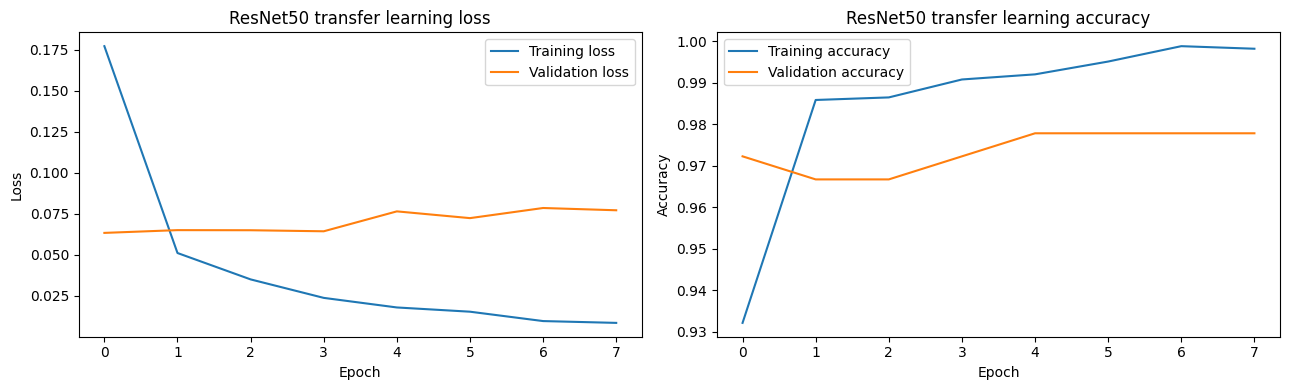

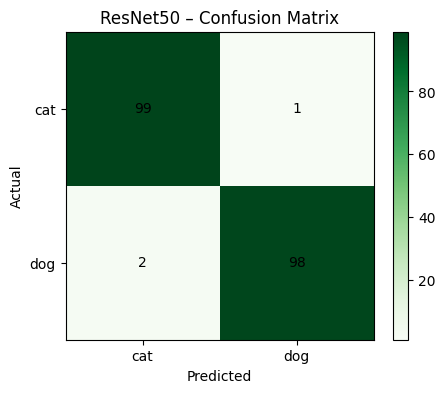

In [22]:
# Transfer learning curves and confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(tl_history.history["loss"], label="Training loss")
axes[0].plot(tl_history.history["val_loss"], label="Validation loss")
axes[0].set_title("ResNet50 transfer learning loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(tl_history.history["accuracy"], label="Training accuracy")
axes[1].plot(tl_history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("ResNet50 transfer learning accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

cm_tl = confusion_matrix(y_test, tl_y_pred)
plt.figure(figsize=(5, 4))
plt.imshow(cm_tl, cmap="Greens")
plt.title("ResNet50 – Confusion Matrix")
plt.xticks(range(n_classes), label_names)
plt.yticks(range(n_classes), label_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
for i in range(n_classes):
    for j in range(n_classes):
        plt.text(j, i, cm_tl[i, j], ha="center", va="center")
plt.colorbar()
plt.show()

### 4.1 Sample predictions from the held-out test set\nThe following figure shows the true label and each model's predicted label and confidence for the same test images.

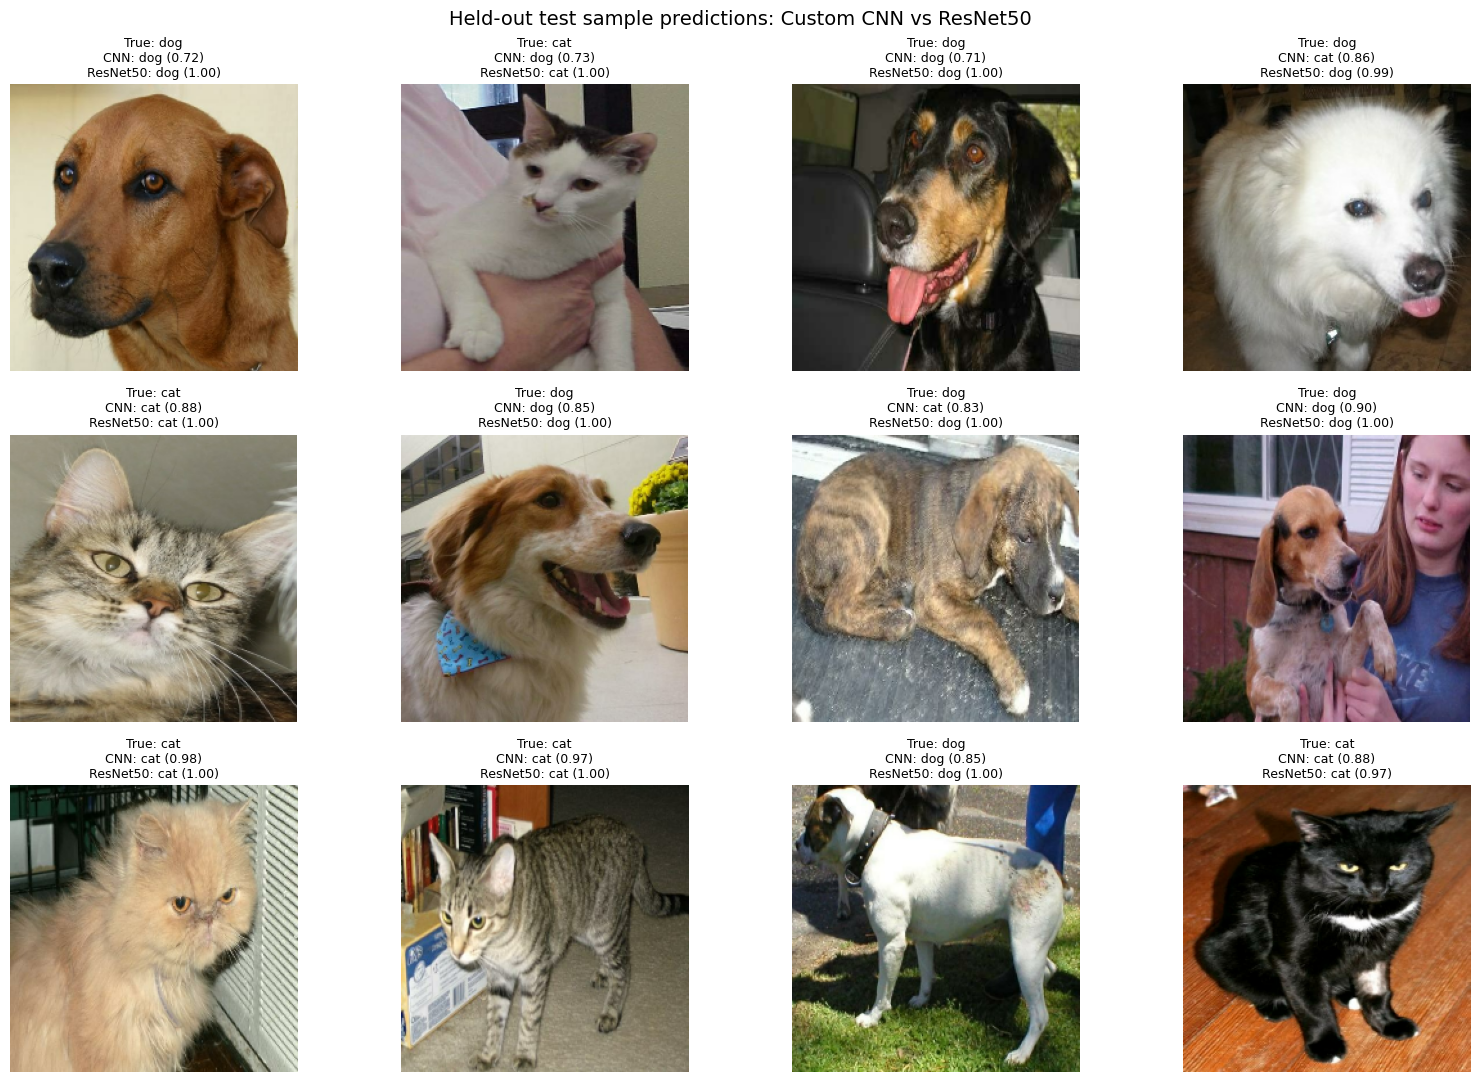

Displayed 12 sample predictions from the held-out test set.


In [23]:
# Sample predictions: compare both models on the same held-out test images
rng = np.random.default_rng(SEED)
sample_indices = rng.choice(len(X_test), size=min(12, len(X_test)), replace=False)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, sample_idx in zip(axes.flat, sample_indices):
    image = X_test[sample_idx]
    true_id = int(y_test[sample_idx])

    cnn_prob = custom_probabilities[sample_idx]
    cnn_pred = int(np.argmax(cnn_prob))
    cnn_conf = float(np.max(cnn_prob))

    resnet_prob = tl_probabilities[sample_idx]
    resnet_pred = int(np.argmax(resnet_prob))
    resnet_conf = float(np.max(resnet_prob))

    ax.imshow(image)
    ax.set_title(
        f"True: {label_names[true_id]}\n"
        f"CNN: {label_names[cnn_pred]} ({cnn_conf:.2f})\n"
        f"ResNet50: {label_names[resnet_pred]} ({resnet_conf:.2f})",
        fontsize=9
    )
    ax.axis("off")

for ax in axes.flat[len(sample_indices):]:
    ax.axis("off")

plt.suptitle("Held-out test sample predictions: Custom CNN vs ResNet50", fontsize=14)
plt.tight_layout()
plt.show()

print("Displayed", len(sample_indices), "sample predictions from the held-out test set.")


## 4. Part 3 – Model comparison and visualization

                 Metric   Custom CNN  Transfer Learning (ResNet50)
               Accuracy 7.700000e-01                  9.850000e-01
        Macro Precision 7.865025e-01                  9.850485e-01
           Macro Recall 7.700000e-01                  9.850000e-01
         Macro F1-score 7.666396e-01                  9.849996e-01
Training Time (seconds) 4.248128e+02                  8.888960e+01
       Total Parameters 1.208290e+06                  2.359181e+07


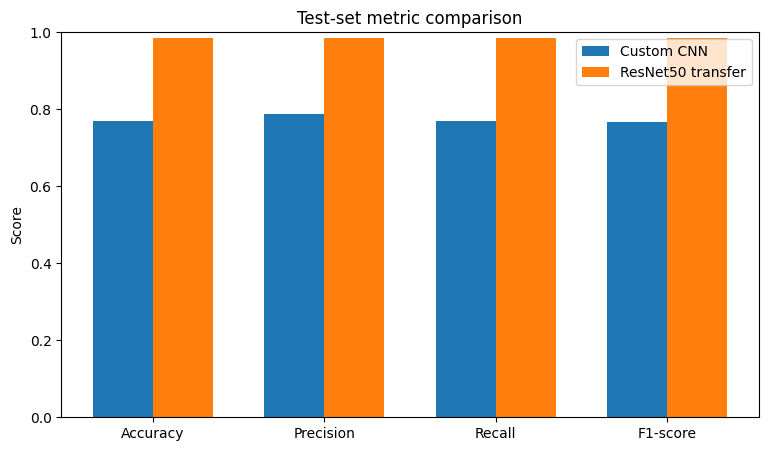

In [24]:
custom_total_parameters = int(custom_cnn.count_params())
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1-score",
               "Training Time (seconds)", "Total Parameters"],
    "Custom CNN": [custom_cnn_accuracy, custom_cnn_precision, custom_cnn_recall,
                   custom_cnn_f1, custom_cnn_training_time, custom_total_parameters],
    "Transfer Learning (ResNet50)": [tl_accuracy, tl_precision, tl_recall,
                                     tl_f1, tl_training_time, total_parameters]
})
print(comparison_df.to_string(index=False))

metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
custom_values = [custom_cnn_accuracy, custom_cnn_precision, custom_cnn_recall, custom_cnn_f1]
tl_values = [tl_accuracy, tl_precision, tl_recall, tl_f1]
x = np.arange(len(metric_names))
width = 0.35
plt.figure(figsize=(9, 5))
plt.bar(x - width/2, custom_values, width, label="Custom CNN")
plt.bar(x + width/2, tl_values, width, label="ResNet50 transfer")
plt.xticks(x, metric_names)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Test-set metric comparison")
plt.legend()
plt.show()

## 5. Part 4 – Analysis (2 marks)

The analysis below is generated from the actual model evaluation values after training. It addresses performance, pre-training, GAP, computational cost, transfer-learning insights and convergence behavior.

In [25]:
# Generate a concise, results-based analysis from the actual run
best_model_name = "ResNet50 transfer learning" if tl_accuracy >= custom_cnn_accuracy else "Custom CNN"
accuracy_gap = abs(tl_accuracy - custom_cnn_accuracy)
custom_reduction = (
    (custom_cnn_initial_loss - custom_cnn_final_loss) / custom_cnn_initial_loss * 100
)
tl_reduction = (tl_initial_loss - tl_final_loss) / tl_initial_loss * 100

analysis_text = (
    f"{best_model_name} performed better on test accuracy by an absolute "
    f"{accuracy_gap:.3f}. Custom CNN accuracy, macro precision, recall and F1 "
    f"were {custom_cnn_accuracy:.3f}, {custom_cnn_precision:.3f}, "
    f"{custom_cnn_recall:.3f} and {custom_cnn_f1:.3f}; ResNet50 achieved "
    f"{tl_accuracy:.3f}, {tl_precision:.3f}, {tl_recall:.3f} and {tl_f1:.3f}. "
    f"ImageNet pre-training supplies reusable visual features and generally "
    f"improves convergence when labelled data are limited compared with training "
    f"from scratch. Both models use Global Average Pooling (GAP), which reduces "
    f"the classifier head's parameter count compared with Flatten and can help "
    f"control overfitting. The Custom CNN has {custom_total_parameters:,} "
    f"parameters; ResNet50 has {total_parameters:,}, of which "
    f"{trainable_parameters:,} are trainable because its base layers are frozen. "
    f"Training took {custom_cnn_training_time:.1f}s for the Custom CNN and "
    f"{tl_training_time:.1f}s for ResNet50. Training-loss reductions were "
    f"{custom_reduction:.1f}% and {tl_reduction:.1f}%, showing their different "
    f"convergence behaviour. Transfer learning offers strong accuracy with a "
    f"small trainable head, while a custom CNN is substantially smaller and "
    f"allows architecture-specific learning."
)

print("ANALYSIS")
print(analysis_text)
print("Analysis word count:", len(analysis_text.split()))
if len(analysis_text.split()) > 200:
    print("Note: The assignment describes 200 words as a guideline; quality is prioritized.")


ANALYSIS
ResNet50 transfer learning performed better on test accuracy by an absolute 0.215. Custom CNN accuracy, macro precision, recall and F1 were 0.770, 0.787, 0.770 and 0.767; ResNet50 achieved 0.985, 0.985, 0.985 and 0.985. ImageNet pre-training supplies reusable visual features and generally improves convergence when labelled data are limited compared with training from scratch. Both models use Global Average Pooling (GAP), which reduces the classifier head's parameter count compared with Flatten and can help control overfitting. The Custom CNN has 1,208,290 parameters; ResNet50 has 23,591,810, of which 4,098 are trainable because its base layers are frozen. Training took 424.8s for the Custom CNN and 88.9s for ResNet50. Training-loss reductions were 51.9% and 95.2%, showing their different convergence behaviour. Transfer learning offers strong accuracy with a small trainable head, while a custom CNN is substantially smaller and allows architecture-specific learning.
Analysis wor

## 6. Environment verification and final submission checklist

**Required by the assignment:** Insert a screenshot from your Google Colab or BITS Virtual Lab environment showing your account details and the notebook name. Do not fabricate or programmatically generate this screenshot; capture it from your actual environment and paste it into a Markdown cell below.

In [26]:
print("ENVIRONMENT INFORMATION")
print("Python:", sys.version)
print("Platform:", platform.platform())
print("TensorFlow:", tf.__version__)
print("Execution date:", datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("\nREQUIRED: Add your own Colab/BITS Virtual Lab screenshot in a Markdown cell below.")

ENVIRONMENT INFORMATION
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
TensorFlow: 2.21.0
Execution date: 2026-11-27 03:15:08
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

REQUIRED: Add your own Colab/BITS Virtual Lab screenshot in a Markdown cell below.


### Environment screenshot – insert your own screenshot here

Paste a genuine screenshot captured from your Google Colab or BITS Virtual Lab session. It should show the notebook title and the signed-in account/session as requested in the assignment. Do not use a fabricated or edited screenshot.


### Final checklist – complete before LMS submission

- [ ] Rename/download the executed notebook as `2026CT05135 cnn assignment.ipynb`.
- [ ] BITS ID in filename matches notebook: `2026CT05135`.
- [ ] Student name matches LMS: `Amit Jhariya`.
- [ ] Confirm the LMS submission folder name exactly matches the student name.
- [ ] Run **Runtime → Restart session and Run all** in Google Colab.
- [ ] Confirm every code cell completes without errors and all outputs are visible.
- [ ] Confirm at least 500 images per class and a 90/10 or 85/15 train/test split.
- [ ] Both models use GlobalAveragePooling2D; neither classifier head uses Flatten.
- [ ] ResNet50 base layers are frozen and the custom head is trainable.
- [ ] Both models have actual initial/final loss, training time and all four non-zero test metrics.
- [ ] Check the Custom CNN loss reduction against the strict 20% threshold; do not alter reported values manually.
- [ ] Training curves, confusion matrices and sample predictions are visible.
- [ ] Analysis is generated from the current run and discusses performance, pre-training, GAP, computational cost and convergence.
- [ ] Final JSON is printed at the end and passes all validation assertions.
- [ ] Insert a genuine Colab/BITS Virtual Lab screenshot in the screenshot placeholder above.
- [ ] Submit only the `.ipynb` file (no ZIP, dataset or separate data files).

**Do not submit this notebook before executing it successfully.** This revised file contains the improved training code, but the revised model metrics and JSON are intentionally left to be generated by your own Colab run. The previous run's outputs have been cleared so stale results cannot be mistaken for the new run.


In [27]:
def get_assignment_results():
    """
    Generate complete assignment results in the required format.
    The key structure follows the supplied assignment template.
    """
    framework_used = "keras"

    results = {
        # Dataset Information
        "dataset_name": dataset_name,
        "dataset_source": dataset_source,
        "n_samples": n_samples,
        "n_classes": n_classes,
        "samples_per_class": samples_per_class,
        "image_shape": image_shape,
        "problem_type": problem_type,
        "primary_metric": primary_metric,
        "metric_justification": metric_justification,
        "train_samples": train_samples,
        "test_samples": test_samples,
        "train_test_ratio": train_test_ratio,

        # Custom CNN Results
        "custom_cnn": {
            "framework": framework_used,
            "architecture": {
                "conv_layers": sum(isinstance(layer, tf.keras.layers.Conv2D) for layer in custom_cnn.layers),
                "pooling_layers": sum(isinstance(layer, (tf.keras.layers.MaxPooling2D, tf.keras.layers.AveragePooling2D)) for layer in custom_cnn.layers),
                "has_global_average_pooling": True,
                "output_layer": "softmax",
                "total_parameters": custom_total_parameters
            },
            "training_config": {
                "learning_rate": custom_learning_rate,
                "n_epochs": len(custom_history.history["loss"]),
                "batch_size": custom_batch_size,
                "optimizer": custom_optimizer,
                "loss_function": custom_loss_function
            },
            "initial_loss": custom_cnn_initial_loss,
            "final_loss": custom_cnn_final_loss,
            "training_time_seconds": custom_cnn_training_time,
            "accuracy": custom_cnn_accuracy,
            "precision": custom_cnn_precision,
            "recall": custom_cnn_recall,
            "f1_score": custom_cnn_f1
        },

        # Transfer Learning Results
        "transfer_learning": {
            "framework": framework_used,
            "base_model": pretrained_model_name,
            "frozen_layers": frozen_layers,
            "trainable_layers": trainable_layers,
            "has_global_average_pooling": True,
            "total_parameters": total_parameters,
            "trainable_parameters": trainable_parameters,
            "training_config": {
                "learning_rate": tl_learning_rate,
                "n_epochs": len(tl_history.history["loss"]),
                "batch_size": tl_batch_size,
                "optimizer": tl_optimizer,
                "loss_function": "sparse_categorical_crossentropy"
            },
            "initial_loss": tl_initial_loss,
            "final_loss": tl_final_loss,
            "training_time_seconds": tl_training_time,
            "accuracy": tl_accuracy,
            "precision": tl_precision,
            "recall": tl_recall,
            "f1_score": tl_f1
        },

        # Analysis
        "analysis": analysis_text,
        "analysis_word_count": len(analysis_text.split()),

        # Training Success Indicators
        "custom_cnn_loss_decreased": custom_cnn_final_loss < custom_cnn_initial_loss,
        "transfer_learning_loss_decreased": tl_final_loss < tl_initial_loss
    }

    return results

print("get_assignment_results() function defined successfully.")

get_assignment_results() function defined successfully.


In [28]:
# Final strict validation and required JSON output
assignment_results = get_assignment_results()

required_top_level = [
    "dataset_name", "dataset_source", "n_samples", "n_classes",
    "samples_per_class", "image_shape", "problem_type",
    "primary_metric", "metric_justification", "train_samples",
    "test_samples", "train_test_ratio", "custom_cnn",
    "transfer_learning", "analysis"
]
missing_top_level = [key for key in required_top_level if key not in assignment_results]
assert not missing_top_level, f"Missing top-level JSON keys: {missing_top_level}"

required_metrics = ["accuracy", "precision", "recall", "f1_score"]
for model_key in ["custom_cnn", "transfer_learning"]:
    model_result = assignment_results[model_key]
    has_gap = (
        model_result["architecture"]["has_global_average_pooling"]
        if model_key == "custom_cnn"
        else model_result["has_global_average_pooling"]
    )
    assert has_gap is True, f"{model_key} is missing Global Average Pooling"
    for metric in required_metrics:
        value = float(model_result[metric])
        assert np.isfinite(value) and 0.0 <= value <= 1.0, (
            f"Invalid {model_key} {metric}: {value}"
        )
        assert value > 0.0, f"{model_key} {metric} is zero; inspect training/evaluation."

assert any(isinstance(layer, tf.keras.layers.Conv2D) for layer in custom_cnn.layers)
assert any(isinstance(layer, tf.keras.layers.GlobalAveragePooling2D) for layer in custom_cnn.layers)
assert not any(isinstance(layer, tf.keras.layers.Flatten) for layer in custom_cnn.layers)
assert not transfer_base_model.trainable, "ResNet50 base layers must remain frozen"
assert any(isinstance(layer, tf.keras.layers.GlobalAveragePooling2D) for layer in transfer_model.layers)
assert assignment_results["train_test_ratio"] in ["90/10", "85/15"]
assert 2 <= assignment_results["n_classes"] <= 20
assert assignment_results["n_samples"] >= 500 * assignment_results["n_classes"]
assert min(class_counts.values()) >= 500
assert assignment_results["custom_cnn"]["initial_loss"] > 0
assert assignment_results["custom_cnn"]["final_loss"] > 0
assert assignment_results["transfer_learning"]["initial_loss"] > 0
assert assignment_results["transfer_learning"]["final_loss"] > 0
assert len(analysis_text.split()) > 50, "Analysis is too short for the rubric."

print("All architecture, dataset, metric and JSON validation checks passed.")
print("\\nCUSTOM CNN CONVERGENCE CHECK")
print(f"Loss reduction: {custom_cnn_loss_reduction_pct:.2f}%")
if custom_cnn_loss_reduction_pct >= 50:
    print("Meets the strict >=50% threshold for 2/2 convergence marks.")
elif custom_cnn_loss_reduction_pct >= 20:
    print("Meets the strict >=20% threshold for 1/2 convergence marks.")
else:
    print("WARNING: Below the strict 20% threshold; this section may receive 0/2.")
print("\\nASSIGNMENT RESULTS SUMMARY – JSON")
print(json.dumps(assignment_results, indent=2))


All architecture, dataset, metric and JSON validation checks passed.
\nCUSTOM CNN CONVERGENCE CHECK
Loss reduction: 51.93%
Meets the strict >=50% threshold for 2/2 convergence marks.
\nASSIGNMENT RESULTS SUMMARY – JSON
{
  "dataset_name": "Cats vs Dogs (TensorFlow Datasets; balanced subset)",
  "dataset_source": "https://www.tensorflow.org/datasets/catalog/cats_vs_dogs",
  "n_samples": 2000,
  "n_classes": 2,
  "samples_per_class": "min: 1000, max: 1000, avg: 1000",
  "image_shape": [
    224,
    224,
    3
  ],
  "problem_type": "classification",
  "primary_metric": "accuracy",
  "metric_justification": "Accuracy is the primary metric because the selected dataset is balanced with the same number of cat and dog images. Macro precision, recall and F1-score are also reported to assess both classes equally.",
  "train_samples": 1800,
  "test_samples": 200,
  "train_test_ratio": "90/10",
  "custom_cnn": {
    "framework": "keras",
    "architecture": {
      "conv_layers": 8,
      "pooli